# 03 · Validation (Ludovico)

**Question:** how do we estimate the Kaggle score **honestly**, before submitting?

**Principle:** a validation split is only useful if it **looks like the real train → test split**. So we first describe the real split, then build candidate schemes and keep the one that copies it best.

**Ground rules**
- Every scheme is tested with the **same simple model**, so differences come from the scheme, not the model.
- All preprocessing sits **inside a Pipeline**, fitted on the training fold only.
- The test set is never used to choose anything.

<div class="alert alert-block alert-info">

# TOC<a class="anchor" id="toc"></a>
* [<font color='#E8800A'>Setup</font>](#setup)
* [<font color='#E8800A'>1. The real split: train → test</font>](#real)
* [<font color='#E8800A'>2. Candidate schemes</font>](#schemes)
* [<font color='#E8800A'>3. Do the schemes look like the real split?</font>](#describe)
* [<font color='#E8800A'>4. Comparison with a fixed baseline model</font>](#compare)
* [<font color='#E8800A'>5. Decision threshold</font>](#threshold)
* [<font color='#E8800A'>6. Chosen scheme and summary</font>](#summary)

</div>

# <font color='#E8800A'>Setup</font> <a class="anchor" id="setup"></a>
[Back to TOC](#toc)

**Clean data:** the cleaning rules live in `cleaning_ludovico.ipynb` for now. `%run` executes that notebook and gives back `train_clean` and `test_clean` (`%%capture` hides its output).

Once `clean()` is moved to `src/cleaning.py`, replace this cell with `from src.cleaning import clean, drop_empty_rows`.

In [1]:
%%capture
%run ./cleaning_ludovico.ipynb

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.model_selection import GroupKFold, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
PLOT_BLUE, PLOT_ORANGE = "#1779A8", "#C96A00"
FIGSIZE = (10, 5)
RANDOM_STATE = 42
TARGET = "repeat_purchase_90d"
GAP_DAYS = 90  # target horizon: a training label looks this many days into the future

In [3]:
train = train_clean
test = test_clean

y = train[TARGET]
dates = train["purchase_date"]
customers = train["customer_id"]

# Not features: identifiers, raw date, and the decoy column (EDA Step 20)
NOT_FEATURES = [TARGET, "customer_id", "purchase_date", "random_noise"]
X = train.drop(columns=NOT_FEATURES)

print(f"train: {len(train):,} rows, {X.shape[1]} features | test: {len(test):,} rows")

train: 6,469 rows, 34 features | test: 986 rows


# <font color='#E8800A'>1. The real split: train → test</font> <a class="anchor" id="real"></a>
[Back to TOC](#toc)

**Goal:** write down the properties of the real split. Every scheme below is compared against this row.

| Property | Why it matters |
|---|---|
| Test is **later** than train, with a gap | the model always predicts the future |
| Gap ≥ 90 days | no training label looks into the test period |
| Size of test | validation folds of a similar size give a similar amount of noise |
| Share of test rows from **customers already seen** | tells us whether to validate on known or unseen customers |
| Positive rate | it drifts by year, and it sets the F1 floor of "always predict 1" |

In [4]:
def describe_split(train_part, val_part, name):
    """The properties of one train -> validation split, comparable with the real train -> test split."""
    train_dates, val_dates = train_part["purchase_date"], val_part["purchase_date"]
    row = {
        "scheme": name,
        "train rows": len(train_part),
        "val rows": len(val_part),
        "val period": f"{val_dates.min():%Y-%m} -> {val_dates.max():%Y-%m}",
        "gap days": (val_dates.min() - train_dates.max()).days,  # negative = train and val overlap in time
        "train rows after val start": (train_dates > val_dates.min()).mean(),
        "seen customers": val_part["customer_id"].isin(train_part["customer_id"]).mean(),
    }
    if TARGET in val_part:
        rate = val_part[TARGET].mean()
        row["val positive rate"] = rate
        row["F1 always 1"] = 2 * rate / (1 + rate)
    return row


real = pd.DataFrame([describe_split(train, test, "REAL: train -> test")]).set_index("scheme")
real.style.format({"train rows after val start": "{:.1%}", "seen customers": "{:.1%}"})

,train rows,val rows,val period,gap days,train rows after val start,seen customers
scheme,,,,,,
REAL: train -> test,6469,986,2025-05 -> 2026-10,98,0.0%,94.5%


**The target to copy:** future-only training (0% of training rows after the start of test), a gap just above 90 days, about 1,000 validation rows, and about 95% of validation rows from known customers.

The test labels are hidden, so its positive rate is unknown. In train it drifts between about 0.48 and 0.63 per year (EDA Step 10).

# <font color='#E8800A'>2. Candidate schemes</font> <a class="anchor" id="schemes"></a>
[Back to TOC](#toc)

| Scheme | How it splits | What it simulates | Expected |
|---|---|---|---|
| **Random K-fold** | stratified shuffle, 5 folds | nothing realistic: trains on the future, same customer on both sides | too optimistic, reference only |
| **Group K-fold** | 5 folds, a customer is never on both sides | **unseen** customers | too pessimistic: 95% of test customers are known |
| **Time CV, no gap** | train on the past, validate on the next block | time order, but labels leak | slightly optimistic |
| **Time holdout + gap** | one cut-off, validate on the last ~14 months | the real split, once | realistic, but one fold = noisy |
| **Time CV + gap** | 3 cut-offs, each validates on the next year | the real split, three times | realistic and more stable |

**Why the 90-day gap?** A training row from 1 December has a label that says "did the customer buy again before 1 March?". If validation starts on 1 January, that label already contains information from the validation period. Leaving 90 days between the last training row and the first validation row removes this leak.

**Why split on dates and not rows?** `TimeSeriesSplit(gap=90)` counts **rows**. With a very irregular monthly volume, 90 rows can mean two weeks or six months, so the generator below works with dates.

In [5]:
def time_splits(dates, val_starts, gap_days=GAP_DAYS):
    """Expanding-window time splits on dates.

    Fold k validates on [val_starts[k], val_starts[k+1]) (the last fold runs to the end of the data)
    and trains on every row strictly before val_starts[k] - gap_days.
    Yields (train_idx, val_idx) as positional indices, so it can be passed as `cv=` to sklearn.
    """
    dates = pd.to_datetime(pd.Series(dates)).reset_index(drop=True)
    starts = list(pd.to_datetime(val_starts)) + [dates.max() + pd.Timedelta(days=1)]
    for start, end in zip(starts[:-1], starts[1:]):
        train_idx = np.flatnonzero(dates < start - pd.Timedelta(days=gap_days))
        val_idx = np.flatnonzero((dates >= start) & (dates < end))
        yield train_idx, val_idx

**Cut-offs.** The last 14 months of train (2024-01 → 2025-02) hold about 835 rows, close to the 986 test rows. The time CV adds two earlier yearly blocks, so each fold has ~600–800 rows.

In [6]:
TIME_CV_STARTS = ["2022-01-01", "2023-01-01", "2024-01-01"]
HOLDOUT_START = ["2024-01-01"]

schemes = {
    "random K-fold": list(StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(X, y)),
    "group K-fold (customer)": list(GroupKFold(5, shuffle=True, random_state=RANDOM_STATE).split(X, y, groups=customers)),
    "time CV, no gap": list(time_splits(dates, TIME_CV_STARTS, gap_days=0)),
    "time holdout + gap": list(time_splits(dates, HOLDOUT_START)),
    "time CV + gap": list(time_splits(dates, TIME_CV_STARTS)),
}
pd.Series({name: len(splits) for name, splits in schemes.items()}, name="folds").to_frame()

,folds
random K-fold,5
group K-fold (customer),5
"time CV, no gap",3
time holdout + gap,1
time CV + gap,3


# <font color='#E8800A'>3. Do the schemes look like the real split?</font> <a class="anchor" id="describe"></a>
[Back to TOC](#toc)

**Check:** apply `describe_split` to every fold of every scheme and put the real split on top. A good scheme has numbers close to the first row.

In [7]:
fold_table = pd.DataFrame([
    describe_split(train.iloc[tr], train.iloc[va], f"{name} · fold {k}")
    for name, splits in schemes.items()
    for k, (tr, va) in enumerate(splits, 1)
]).set_index("scheme")

pd.concat([real, fold_table]).style.format({
    "train rows after val start": "{:.1%}", "seen customers": "{:.1%}",
    "val positive rate": "{:.3f}", "F1 always 1": "{:.3f}",
}, na_rep="?")

,train rows,val rows,val period,gap days,train rows after val start,seen customers,val positive rate,F1 always 1
scheme,,,,,,,,
REAL: train -> test,6469,986,2025-05 -> 2026-10,98,0.0%,94.5%,?,?
random K-fold · fold 1,5175,1294,2015-07 -> 2025-02,-3506,99.3%,96.3%,0.560,0.718
random K-fold · fold 2,5175,1294,2015-07 -> 2025-02,-3506,99.4%,96.8%,0.560,0.718
random K-fold · fold 3,5175,1294,2015-07 -> 2025-02,-3506,99.3%,97.1%,0.560,0.718
random K-fold · fold 4,5175,1294,2015-07 -> 2025-02,-3507,100.0%,96.8%,0.560,0.718
random K-fold · fold 5,5176,1293,2015-07 -> 2025-02,-3507,100.0%,97.1%,0.560,0.718
group K-fold (customer) · fold 1,5326,1143,2015-07 -> 2025-02,-3507,100.0%,0.0%,0.490,0.658
group K-fold (customer) · fold 2,5163,1306,2015-07 -> 2025-02,-3506,99.3%,0.0%,0.596,0.747
group K-fold (customer) · fold 3,5250,1219,2015-07 -> 2025-02,-3507,100.0%,0.0%,0.573,0.729


**Reading the table**
- **Random and group K-fold** validate on the whole 2015 → 2025 period, and **99–100% of their training rows are later** than the start of validation, so they train on the future. The negative "gap" means train and validation overlap in time.
- **Random K-fold** gets the share of seen customers right (~97% vs 94.5%) but the time order wrong.
- **Group K-fold** has **0% seen customers**, the opposite of test (94.5%). It answers a different question: how well do we predict *new* customers?
- **Time schemes** copy the real split best: no future rows, a gap of 91 days (real: 98), 628–835 validation rows (real: 986), 90–91% seen customers (real: 94.5%).
- **Time CV, no gap** has a gap of only 1–3 days, so the last training labels look into the validation period.
- **The positive rate drifts** across time folds (0.48 → 0.58 → 0.61), so the "always 1" floor moves from 0.649 to 0.754. Random folds hide this drift (always 0.56).

# <font color='#E8800A'>4. Comparison with a fixed baseline model</font> <a class="anchor" id="compare"></a>
[Back to TOC](#toc)

**Two fixed models, identical for every scheme**, so the differences come from the scheme, not the model:
- **Logistic regression**: simple and rigid, so it can only partly exploit leakage.
- **Gradient boosting** (`HistGradientBoostingClassifier`, default settings): flexible, so it **can** memorise customers and time periods. If a scheme is optimistic, this model shows it.

Shared preprocessing: median imputation + standardisation for numerics, most-frequent imputation + one-hot for categoricals (levels with < 20 rows and unseen levels grouped as "infrequent").

**Metrics per fold**
- **F1** of class 1 at threshold 0.5 (the Kaggle metric).
- **F1 − floor**: F1 minus the F1 of "always predict 1" **on that fold**. The positive rate changes between folds, so the raw F1 alone is misleading.
- **ROC AUC**: ranking quality, independent of the threshold.

In [8]:
preprocess = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
     make_column_selector(dtype_include="number")),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                          OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20,
                                        sparse_output=False)),
     make_column_selector(dtype_include=["string", "object"])),
])
models = {
    "logistic regression": make_pipeline(preprocess, LogisticRegression(max_iter=2000)),
    "gradient boosting": make_pipeline(preprocess, HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
}


def evaluate(model, splits, X, y):
    """Fit a fresh copy of the model on each training fold. Returns per-fold scores and out-of-fold probabilities."""
    rows = []
    oof = pd.Series(np.nan, index=y.index)
    for k, (tr, va) in enumerate(splits, 1):
        fitted = clone(model).fit(X.iloc[tr], y.iloc[tr])
        proba = fitted.predict_proba(X.iloc[va])[:, 1]
        oof.iloc[va] = proba
        y_val = y.iloc[va]
        floor = f1_score(y_val, np.ones(len(y_val)))
        f1 = f1_score(y_val, proba >= 0.5)
        rows.append({"fold": k, "F1": f1, "F1 always 1": floor, "F1 - floor": f1 - floor,
                     "ROC AUC": roc_auc_score(y_val, proba)})
    return pd.DataFrame(rows), oof


# (model, scheme) -> per-fold scores / out-of-fold probabilities
results, oof_predictions = {}, {}
for model_name, model in models.items():
    for name, splits in schemes.items():
        results[model_name, name], oof_predictions[model_name, name] = evaluate(model, splits, X, y)

In [9]:
comparison = pd.DataFrame({
    key: {
        "ROC AUC mean": r["ROC AUC"].mean(),
        "F1 mean": r["F1"].mean(),
        "F1 std": r["F1"].std(),
        "F1 - floor mean": r["F1 - floor"].mean(),
        "folds": len(r),
    }
    for key, r in results.items()
}).T.rename_axis(["model", "scheme"])
comparison.style.format({"ROC AUC mean": "{:.3f}", "F1 mean": "{:.3f}", "F1 std": "{:.3f}",
                         "F1 - floor mean": "{:+.3f}", "folds": "{:.0f}"}, na_rep="-")

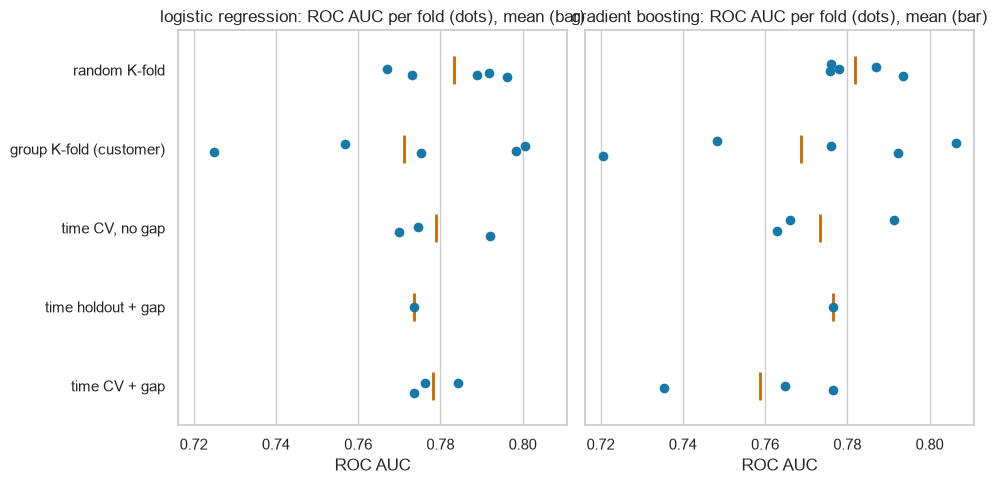

In [10]:
# ROC AUC per fold: threshold-free, so it compares the schemes without the F1-floor effect
per_fold = pd.concat([r.assign(model=m, scheme=s) for (m, s), r in results.items()])

fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, sharey=True, sharex=True)
for ax, model_name in zip(axes, models):
    data = per_fold[per_fold["model"] == model_name]
    sns.stripplot(data=data, y="scheme", x="ROC AUC", color=PLOT_BLUE, size=7, ax=ax)
    sns.pointplot(data=data, y="scheme", x="ROC AUC", color=PLOT_ORANGE, errorbar=None,
                  markers="|", markersize=20, linestyle="none", ax=ax)
    ax.set(title=f"{model_name}: ROC AUC per fold (dots), mean (bar)", ylabel="")
plt.tight_layout()
plt.show()

**Reading the results**
- **Logistic regression barely notices the scheme** (ROC AUC 0.771–0.783). A rigid model can exploit leakage only a little.
- **Gradient boosting shows the optimism clearly:**
  - random K-fold **0.782** vs time CV + gap **0.759** → **+0.023** too optimistic;
  - removing only the gap: 0.759 → 0.773 → **+0.014**, so the 90-day label leak is real;
  - random K-fold also has the **smallest spread** (F1 std 0.004 vs 0.048): it looks precise because every fold is the same mix of years.
- **The scheme changes which model wins.** Random K-fold says the two models are equal (0.783 vs 0.782). Time CV + gap says logistic regression is clearly better (0.778 vs 0.759). Choosing models with random K-fold would therefore mislead us.
- **Group K-fold is not much lower than random here** (0.769–0.771): unseen customers are not dramatically harder. It stays useful as a robustness check, not as the main scheme.
- **Raw F1 is misleading on its own.** The single time holdout has the highest F1 (0.745 / 0.753) only because its positive rate is the highest: **F1 − floor is negative**. This also shows why one fold is not enough.
- **At threshold 0.5 both models are barely above, or below, the "always 1" floor.** The threshold has to be tuned (section 5).

# <font color='#E8800A'>5. Decision threshold</font> <a class="anchor" id="threshold"></a>
[Back to TOC](#toc)

**Problem:** F1 depends on the threshold that turns a probability into 0/1, and 0.5 is rarely the best one. Lowering it trades precision for recall.

**Rule:** choose the threshold **inside the validation scheme**, never on test.
1. Pool the out-of-fold probabilities of **time CV + gap** (logistic regression, the baseline).
2. Find the threshold with the highest F1.
3. Picking the threshold on the same predictions it is scored on is slightly optimistic. For an honest number, also **choose it on folds 1–2 and apply it to fold 3**, the fold closest to test.

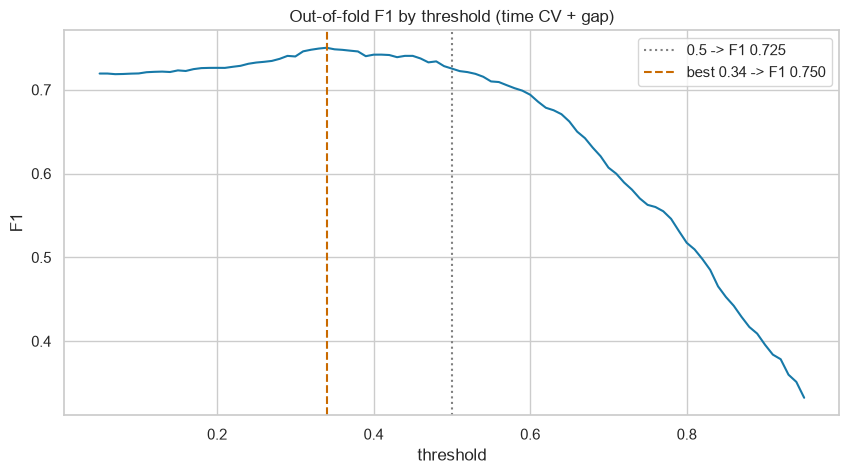

In [11]:
THRESHOLDS = np.round(np.arange(0.05, 0.96, 0.01), 2)


def best_threshold(y_true, proba):
    """Threshold with the highest F1, plus the whole F1 curve."""
    curve = pd.Series([f1_score(y_true, proba >= t) for t in THRESHOLDS], index=THRESHOLDS)
    return curve.idxmax(), curve


oof = oof_predictions["logistic regression", "time CV + gap"]
covered = oof.notna()  # rows that were in a validation fold
t_best, f1_curve = best_threshold(y[covered], oof[covered])

fig, ax = plt.subplots(figsize=FIGSIZE)
ax.plot(f1_curve.index, f1_curve.values, color=PLOT_BLUE)
ax.axvline(0.5, color="grey", ls=":", label=f"0.5 -> F1 {f1_curve[0.5]:.3f}")
ax.axvline(t_best, color=PLOT_ORANGE, ls="--", label=f"best {t_best:.2f} -> F1 {f1_curve[t_best]:.3f}")
ax.set(title="Out-of-fold F1 by threshold (time CV + gap)", xlabel="threshold", ylabel="F1")
ax.legend()
plt.show()

In [12]:
# Honest estimate: threshold chosen on folds 1-2, scored on fold 3
time_folds = schemes["time CV + gap"]
early = np.concatenate([va for _, va in time_folds[:-1]])
last = time_folds[-1][1]

t_early, _ = best_threshold(y.iloc[early], oof.iloc[early])
y_last, p_last = y.iloc[last], oof.iloc[last]

pd.DataFrame({
    "threshold": [0.5, t_early, t_best],
    "chosen on": ["default", "folds 1-2", "all folds (optimistic)"],
    "F1 on fold 3": [f1_score(y_last, p_last >= t) for t in (0.5, t_early, t_best)],
    "F1 always 1 on fold 3": f1_score(y_last, np.ones(len(y_last))),
}).style.format({"threshold": "{:.2f}", "F1 on fold 3": "{:.3f}", "F1 always 1 on fold 3": "{:.3f}"})

,threshold,chosen on,F1 on fold 3,F1 always 1 on fold 3
0,0.50,default,0.745,0.754
1,0.37,folds 1-2,0.771,0.754
2,0.34,all folds (optimistic),0.784,0.754


**Reading the results**
- **The best threshold is about 0.34–0.37, well below 0.5.** F1 on class 1 rewards recall, so predicting 1 more often pays off.
- **Honest estimate on fold 3** (the one closest to test): with the threshold chosen on folds 1–2 (0.37), F1 = **0.771** vs **0.745** at 0.5. That is **+0.017 above the floor** (0.754), while 0.5 was below it.
- The threshold chosen on all folds gives 0.784 on fold 3, but that number is optimistic: the threshold has seen fold 3.

**Rule for `06_models`:** tune the threshold on the out-of-fold predictions of time CV + gap, report the honest "earlier folds → last fold" number, and use the threshold from all folds for the final submission model.

# <font color='#E8800A'>6. Chosen scheme and summary</font> <a class="anchor" id="summary"></a>
[Back to TOC](#toc)

### Decision: time CV with a 90-day gap

| | Chosen scheme | Real train → test |
|---|---|---|
| Validation blocks | 2022, 2023, 2024-01 → 2025-02 | 2025-05 → 2026-10 |
| Training data | everything before block start − 90 days (expanding) | all train |
| Future rows in training | 0% | 0% |
| Gap | 91 days | 98 days |
| Validation rows per fold | 628 / 767 / 835 | 986 |
| Seen customers | 90–91% | 94.5% |

**Why this scheme**
- It is the only one that respects time order **and** the 90-day label horizon, as the real split does.
- Random K-fold is too optimistic (up to +0.023 ROC AUC) and can change which model wins.
- Three folds instead of one holdout: the positive rate drifts by year, so one fold is noisy (see the holdout's misleading F1).

**How to report a model** (from now on, in every notebook)
- ROC AUC and F1 − floor: mean ± std over the 3 folds.
- F1 at the tuned threshold, honest version (threshold from folds 1–2, scored on fold 3).

**Limitations to keep in mind**
- Validation has slightly fewer known customers than test (90% vs 94.5%), so it is, if anything, slightly pessimistic.
- 600–800 rows per fold: differences between models below ~0.02 are within the noise (compare with the std).
- Fold 1 trains on only ~4,000 rows. Later folds are closer to the final model, which is trained on all 6,469 rows.

### Lines for `docs/decisions.md`

| Decision | Alternatives considered | Evidence |
|---|---|---|
| Validation = expanding time CV, 3 yearly blocks (2022, 2023, 2024+), 90-day gap | random K-fold, group K-fold, single time holdout, time CV without gap | `validation_ludovico` §3–4: only scheme matching time order + gap; random K-fold +0.023 ROC AUC optimistic with gradient boosting, gap alone +0.014 |
| Report ROC AUC and F1 − "always 1" floor, mean ± std over folds | raw F1 only | positive rate drifts 0.48–0.61 between folds (§3–4) |
| Tune the decision threshold on out-of-fold predictions | fixed 0.5 | best ≈ 0.35; honest fold-3 F1 0.771 vs 0.745 at 0.5 (§5) |

### Next steps
1. Move `time_splits`, `describe_split`, `evaluate` and `best_threshold` to `src/validation.py`, together with `TIME_CV_STARTS` and `GAP_DAYS`.
2. Use **the same splits** in `04_preprocessing`, `05_features` and `06_models`, so every score is comparable.
3. For the submission: refit the chosen pipeline on **all** train, and predict test with the threshold tuned on the out-of-fold predictions.